# E-commerce Purchases Analysis 

**Goal:** understand how customers spend, when they buy, and which customer segments (card provider, language, job, browser) differ, and check whether those differences are real or just noise.

**Dataset:** 10,000 e-commerce purchases (synthetic data, a public practice dataset). Sensitive fields (card numbers, emails, IP addresses) are **not displayed** in this notebook.

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, SciPy

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:,.2f}'.format

df = pd.read_csv(r'C:\Users\LENOVO\Downloads\Ecommerce Purchases\Ecommerce Purchases')
df.shape

(10000, 14)

## 1. Data quality

In [ ]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Purchases with price = 0:', (df['Purchase Price'] == 0).sum())
df['Purchase Price'].describe()

Missing values: 0
Duplicate rows: 0
Purchases with price = 0: 2


count   10,000.00
mean        50.35
std         29.02
min          0.00
25%         25.15
50%         50.50
75%         75.77
max         99.99
Name: Purchase Price, dtype: float64

## 2. Prepare the data (and protect sensitive fields)

In [ ]:
# Features built from existing columns
df['email_domain'] = df['Email'].str.split('@').str[1]
df['exp_date'] = pd.to_datetime(df['CC Exp Date'], format='%m/%y')
df['exp_year'] = df['exp_date'].dt.year
df['browser'] = df['Browser Info'].str.extract(r'^(\w+)')
df['os'] = np.select(
    [df['Browser Info'].str.contains('Windows'),
     df['Browser Info'].str.contains('Macintosh'),
     df['Browser Info'].str.contains('Linux|X11')],
    ['Windows', 'Mac', 'Linux'], default='Other')
df['is_engineer'] = df['Job'].str.contains('Engineer', case=False)
df['price_band'] = pd.cut(df['Purchase Price'], bins=[-0.01, 25, 50, 75, 100],
                          labels=['0-25', '25-50', '50-75', '75-100'])

# Remove sensitive columns so they can never be displayed or published
df = df.drop(columns=['Credit Card', 'CC Security Code', 'Email', 'IP Address', 'Address', 'Lot', 'CC Exp Date'])
df.head()

,AM or PM,Browser Info,Company,CC Provider,Job,Language,Purchase Price,email_domain,exp_date,exp_year,browser,os,is_engineer,price_band
0,PM,Opera/9.56.(X11; Linux x86_64; sl-SI) Presto/2...,Martinez-Herman,JCB 16 digit,"Scientist, product/process development",el,98.14,yahoo.com,2020-02-01,2020,Opera,Linux,False,75-100
1,PM,Opera/8.93.(Windows 98; Win 9x 4.90; en-US) Pr...,"Fletcher, Richards and Whitaker",Mastercard,Drilling engineer,fr,70.73,reed.com,2018-11-01,2018,Opera,Windows,True,50-75
2,PM,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,"Simpson, Williams and Pham",JCB 16 digit,Customer service manager,de,0.95,morales-harrison.com,2019-08-01,2019,Mozilla,Windows,False,0-25
3,PM,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_8_0 ...,"Williams, Marshall and Buchanan",Discover,Drilling engineer,es,78.04,olson-robinson.info,2024-02-01,2024,Mozilla,Mac,True,75-100
4,AM,Opera/9.58.(X11; Linux x86_64; it-IT) Presto/2...,"Brown, Watson and Andrews",Diners Club / Carte Blanche,Fine artist,es,77.82,gmail.com,2025-10-01,2025,Opera,Linux,False,75-100


## 3. How do customers spend?

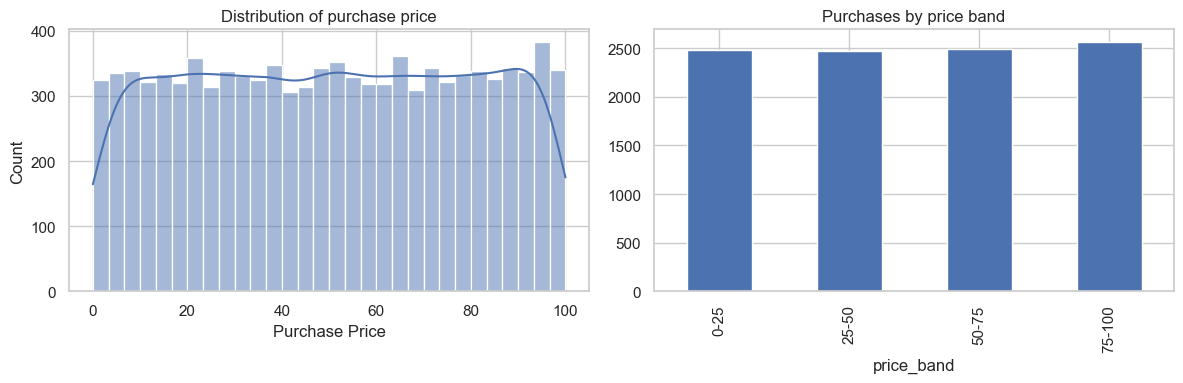

Mean: 50.35 | Median: 50.5


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Purchase Price'], bins=30, kde=True, ax=ax[0])
ax[0].set_title('Distribution of purchase price')
df['price_band'].value_counts().sort_index().plot(kind='bar', ax=ax[1], title='Purchases by price band')
plt.tight_layout(); plt.show()
print('Mean:', round(df['Purchase Price'].mean(), 2), '| Median:', round(df['Purchase Price'].median(), 2))

## 4. When do customers buy? (AM vs PM)

In [ ]:
summary = df.groupby('AM or PM')['Purchase Price'].agg(['count', 'mean', 'median', 'sum'])
summary['share_of_revenue_%'] = summary['sum'] / summary['sum'].sum() * 100
print(summary)

am = df.loc[df['AM or PM'] == 'AM', 'Purchase Price']
pm = df.loc[df['AM or PM'] == 'PM', 'Purchase Price']
t, p = stats.ttest_ind(am, pm, equal_var=False)
print(f'\nT-test AM vs PM: p-value = {p:.3f}')
print('Significant difference' if p < 0.05 else 'No significant difference in average spend')

          count  mean  median        sum  share_of_revenue_%
AM or PM                                                    
AM         4932 50.19   50.01 247,519.87               49.16
PM         5068 50.50   51.04 255,953.15               50.84

T-test AM vs PM: p-value = 0.585
No significant difference in average spend


## 5. Which segments spend more?

In [ ]:
def segment(col, top=None, min_n=30):
    g = df.groupby(col)['Purchase Price'].agg(['count', 'mean', 'median'])
    g = g[g['count'] >= min_n].sort_values('mean', ascending=False)
    return g.head(top) if top else g

print('--- Card provider ---');  print(segment('CC Provider'))
print('\n--- Language ---');     print(segment('Language'))
print('\n--- Operating system ---'); print(segment('os'))
print('\n--- Top 10 email domains by volume ---')
print(df['email_domain'].value_counts().head(10))

--- Card provider ---
                             count  mean  median
CC Provider                                     
Voyager                        829 51.97   52.81
Discover                       817 51.66   52.59
VISA 13 digit                  777 51.45   52.42
JCB 15 digit                   868 51.13   51.91
American Express               849 50.49   51.63
Maestro                        846 50.38   50.30
Mastercard                     816 50.04   49.72
VISA 16 digit                 1715 49.87   49.15
JCB 16 digit                  1716 49.30   49.89
Diners Club / Carte Blanche    767 48.73   47.53

--- Language ---
          count  mean  median
Language                     
el         1137 51.56   51.63
pt         1118 51.22   51.72
en         1098 51.10   52.55
de         1155 50.25   50.35
zh         1059 50.18   49.99
it         1086 50.00   50.75
ru         1155 49.93   51.13
fr         1097 49.48   48.09
es         1095 49.37   48.39

--- Operating system ---
         count  

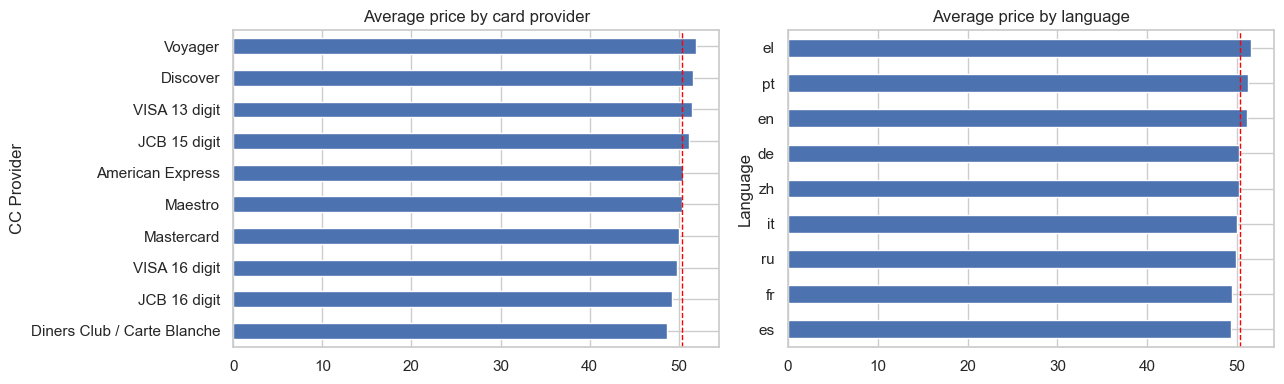

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
segment('CC Provider')['mean'].sort_values().plot(kind='barh', ax=ax[0], title='Average price by card provider')
segment('Language')['mean'].sort_values().plot(kind='barh', ax=ax[1], title='Average price by language')
for a in ax: a.axvline(df['Purchase Price'].mean(), color='red', ls='--', lw=1)
plt.tight_layout(); plt.show()

## 6. Job titles

In [ ]:
top_jobs = df['Job'].value_counts().head(10).index
jobs = df[df['Job'].isin(top_jobs)].groupby('Job')['Purchase Price'].agg(['count', 'mean']).sort_values('mean')
print(jobs)
print('\nEngineers:', df['is_engineer'].sum(), 'customers | avg price', round(df.loc[df['is_engineer'], 'Purchase Price'].mean(), 2),
      'vs others', round(df.loc[~df['is_engineer'], 'Purchase Price'].mean(), 2))

                                   count  mean
Job                                           
Special educational needs teacher     26 44.87
Interior and spatial designer         31 47.30
Charity fundraiser                    26 49.87
Social researcher                     28 50.58
Designer, fashion/clothing            26 52.54
Lawyer                                30 53.46
Designer, jewellery                   27 54.90
Research officer, political party     27 55.14
Purchasing manager                    27 58.44
Dietitian                             26 61.74

Engineers: 984 customers | avg price 49.85 vs others 50.4


## 7. Customer base: card expiry and browsers

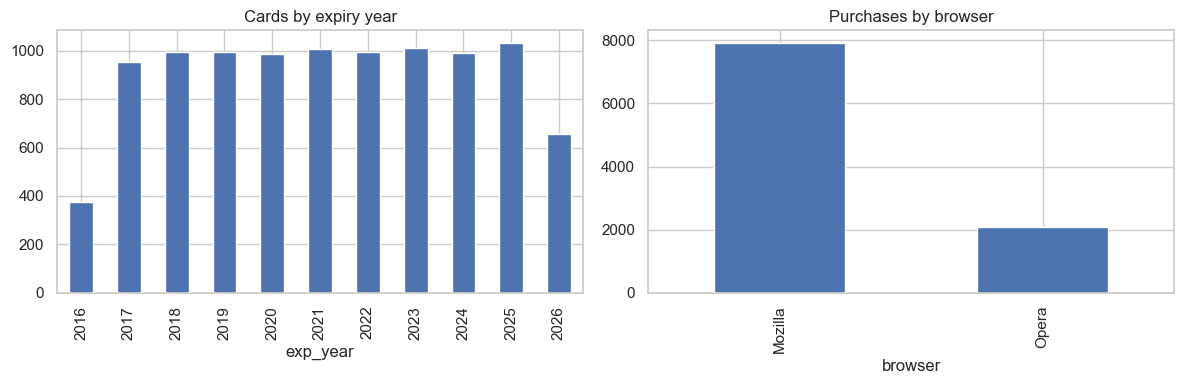

Cards expiring in 2020: 988
French-speaking customers: 1097
Mastercard purchases above 50: 405


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['exp_year'].value_counts().sort_index().plot(kind='bar', ax=ax[0], title='Cards by expiry year')
df['browser'].value_counts().plot(kind='bar', ax=ax[1], title='Purchases by browser')
plt.tight_layout(); plt.show()
print('Cards expiring in 2020:', (df['exp_year'] == 2020).sum())
print('French-speaking customers:', (df['Language'] == 'fr').sum())
print('Mastercard purchases above 50:', ((df['CC Provider'] == 'Mastercard') & (df['Purchase Price'] > 50)).sum())

## 8. Are the differences real? (statistical check)

In [ ]:
groups = [g['Purchase Price'].values for _, g in df.groupby('CC Provider')]
f, p = stats.f_oneway(*groups)
print(f'Average price across card providers: p-value = {p:.3f}')
groups = [g['Purchase Price'].values for _, g in df.groupby('Language')]
f, p = stats.f_oneway(*groups)
print(f'Average price across languages: p-value = {p:.3f}')

Average price across card providers: p-value = 0.261
Average price across languages: p-value = 0.603


A p-value above 0.05 means the differences we see between groups are small enough to be random noise. In this dataset, prices look evenly spread, so finding **no real difference** is also a valid result.